In [2]:
import pandas as pd
import numpy as np
from datasets import Dataset
from sklearn.model_selection import train_test_split
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
from scipy.stats import spearmanr, pearsonr
import joblib


In [ ]:

# 1. Load the Parquet file into a DataFrame
df = pd.read_parquet("data/ava_cleaned_features.parquet")

# 2. Inspect the schema and summary
print(df.info())
print(df.head())

# 3. Extract the feature matrices (X)
# Nested list columns are stacked into 2D NumPy arrays
X_clip = np.vstack(df["clip_embedding"].values).astype(np.float32)       # Shape: (N, 512)
X_struct = np.vstack(df["structural_features"].values).astype(np.float32) # Shape: (N, 12)
X_combined = np.hstack([X_clip, X_struct])                               # Shape: (N, 524)

# 4. Extract target aesthetic scores and metadata
y_mean = df["mean_score"].to_numpy(dtype=np.float32)                     # Target for regressor
y_std = df["std_score"].to_numpy(dtype=np.float32)
image_ids = df["image_id"].to_numpy()
total_votes = df["total_votes"].to_numpy()

print(f"Features shape: {X_combined.shape}, Target shape: {y_mean.shape}")




<class 'pandas.DataFrame'>
RangeIndex: 20420 entries, 0 to 20419
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   image_id             20420 non-null  str    
 1   mean_score           20420 non-null  float64
 2   std_score            20420 non-null  float64
 3   total_votes          20420 non-null  int64  
 4   rating_counts        20420 non-null  object 
 5   structural_features  20420 non-null  object 
 6   clip_embedding       20420 non-null  object 
dtypes: float64(2), int64(1), object(3), str(1)
memory usage: 1.2+ MB
None
  image_id  mean_score  std_score  total_votes  \
0   111875    5.807692   1.670312          208   
1   287132    4.852174   1.671986          230   
2   712748    4.763514   1.275346          148   
3    60556    5.918239   1.504578          159   
4   522313    5.065089   1.192392          169   

                          rating_counts  \
0   [1, 2, 7, 34, 53, 50, 28, 19, 

In [7]:
# Names of the 12 structural features extracted in Step 3 & 4
struct_names = [
    "brightness", "contrast", "center_ratio",
    "r_mean", "g_mean", "b_mean",
    "r_std", "g_std", "b_std",
    "aspect_ratio", "width", "height"
]

# 3. Find the indices of the top 5 highest rated images
top_k = 5
top_indices = np.argsort(y_mean)[::-1][:top_k]

# 4. Display the results
print("=" * 80)
print(f"TOP {top_k} HIGHEST-RATED AVA IMAGES & THEIR FEATURE VALUES")
print("=" * 80)

for rank, idx in enumerate(top_indices, start=1):
    row = df.iloc[idx]
    clip_vec = X_clip[idx]
    struct_vec = X_struct[idx]
    
    print(f"\n--- [Rank {rank}] Image ID: {row['image_id']} ---")
    print(f"Mean Score: {row['mean_score']:.4f} | Votes: {row['total_votes']} | Std: {row['std_score']:.4f}")
    
    print("\nX_struct (12 Structural Features):")
    for name, val in zip(struct_names, struct_vec):
        if name in ["width", "height"]:
            print(f"  {name:15s}: {val:8.0f}")
        else:
            print(f"  {name:15s}: {val:8.4f}")
            
    print("\nX_clip (512-dim Embedding summary):")
    print(f"  Vector Shape    : {clip_vec.shape}")
    print(f"  L2 Norm         : {np.linalg.norm(clip_vec):.4f} (unit sphere check)")
    print(f"  First 8 values  : {np.round(clip_vec[:8], 4).tolist()}")
    print(f"  Min / Max / Mean: {clip_vec.min():.4f} / {clip_vec.max():.4f} / {clip_vec.mean():.4f}")
    print("-" * 80)

TOP 5 HIGHEST-RATED AVA IMAGES & THEIR FEATURE VALUES

--- [Rank 1] Image ID: 34000 ---
Mean Score: 8.0584 | Votes: 137 | Std: 1.5927

X_struct (12 Structural Features):
  brightness     :   0.5517
  contrast       :   0.1118
  center_ratio   :   0.9389
  r_mean         :   0.4179
  g_mean         :   0.5810
  b_mean         :   0.7514
  r_std          :   0.1010
  g_std          :   0.1281
  b_std          :   0.1753
  aspect_ratio   :   0.7066
  width          :      448
  height         :      634

X_clip (512-dim Embedding summary):
  Vector Shape    : (512,)
  L2 Norm         : 1.0000 (unit sphere check)
  First 8 values  : [0.008999999612569809, 0.05339999869465828, -0.023099999874830246, 0.012000000104308128, -0.02250000089406967, 0.008700000122189522, -0.0035000001080334187, 0.0008999999845400453]
  Min / Max / Mean: -0.6697 / 0.1960 / -0.0012
--------------------------------------------------------------------------------

--- [Rank 2] Image ID: 429294 ---
Mean Score: 8.0435 |

c:\Users\Asus\imola\dtu\semester1\datascience\project\aesthetic-unsplash-image-analysis\.venv\Lib\site-packages\PIL\TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 700
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
c:\Users\Asus\imola\dtu\semester1\datascience\project\aesthetic-unsplash-image-analysis\.venv\Lib\site-packages\PIL\TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 33723
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
c:\Users\Asus\imola\dtu\semester1\datascience\project\aesthetic-unsplash-image-analysis\.venv\Lib\site-packages\PIL\TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 34377
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
c:\Users\Asus\imola\dtu\semester1\datascience\project\aesthetic-unsplash-image-analysis\.venv\Lib\site-packages\PIL\TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 34675
  warnin

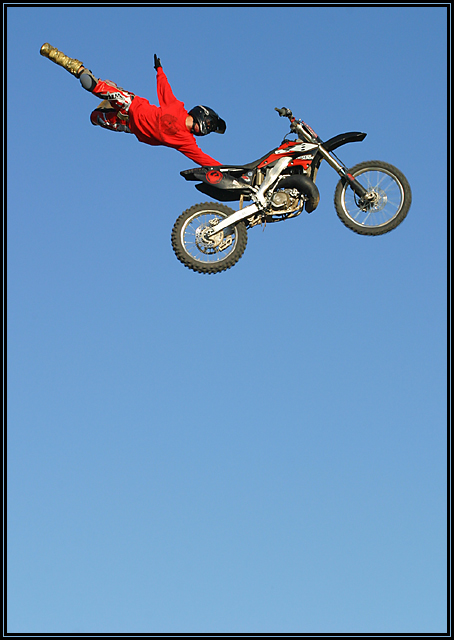

In [8]:
from datasets import load_dataset
ds = load_dataset("trojblue/AVA-aesthetics-10pct-min50-10bins", split="train", streaming=True)
for item in ds:
    if str(item["image_id"]) == "34000":
        display(item["image"])
        break

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 13790.67it/s]


Streaming dataset to find top images...


c:\Users\Asus\imola\dtu\semester1\datascience\project\aesthetic-unsplash-image-analysis\.venv\Lib\site-packages\PIL\TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 700
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
c:\Users\Asus\imola\dtu\semester1\datascience\project\aesthetic-unsplash-image-analysis\.venv\Lib\site-packages\PIL\TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 33723
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
c:\Users\Asus\imola\dtu\semester1\datascience\project\aesthetic-unsplash-image-analysis\.venv\Lib\site-packages\PIL\TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 34377
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
c:\Users\Asus\imola\dtu\semester1\datascience\project\aesthetic-unsplash-image-analysis\.venv\Lib\site-packages\PIL\TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 34675
  warnin


[Rank 1] Image ID: 34000 | Score: 8.0584 | Votes: 137


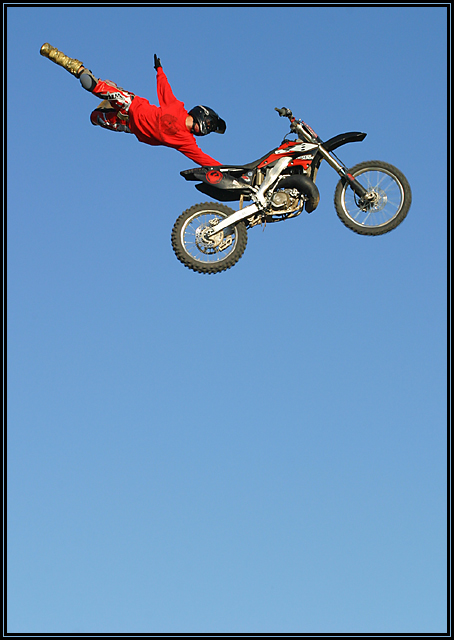

Top 3 Semantic Concept Matches:
  Similarity: 0.214 -> an abstract minimalist composition
  Similarity: 0.213 -> an animal, wildlife, or bird
  Similarity: 0.182 -> water, ocean, lake, or sea
--------------------------------------------------------------------------------

[Rank 2] Image ID: 429294 | Score: 8.0435 | Votes: 230


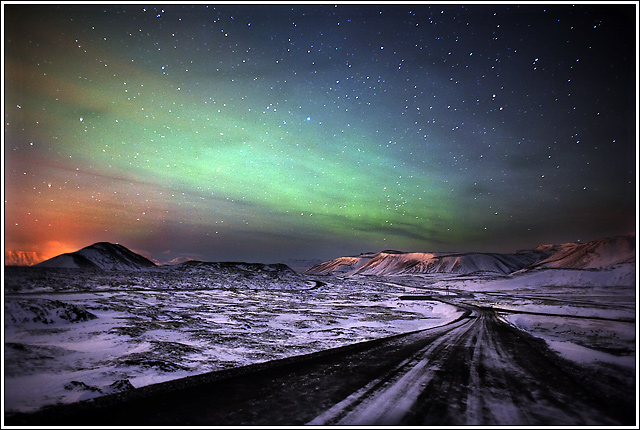

Top 3 Semantic Concept Matches:
  Similarity: 0.217 -> water, ocean, lake, or sea
  Similarity: 0.214 -> a dramatic golden sunset or sunrise
  Similarity: 0.202 -> an animal, wildlife, or bird
--------------------------------------------------------------------------------

[Rank 3] Image ID: 218759 | Score: 7.9065 | Votes: 492


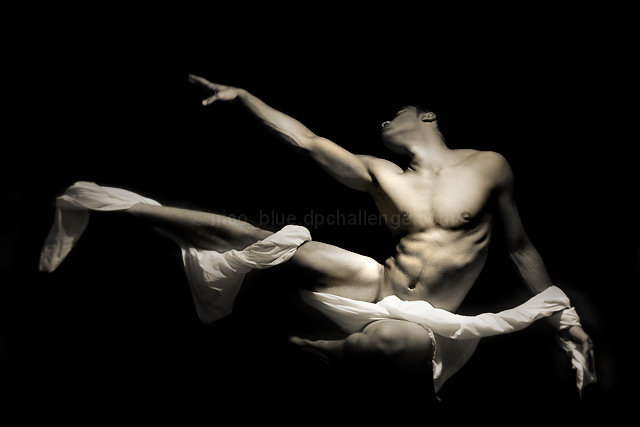

Top 3 Semantic Concept Matches:
  Similarity: 0.244 -> a monochrome black and white photo
  Similarity: 0.220 -> a dark moody silhouette
  Similarity: 0.213 -> an abstract minimalist composition
--------------------------------------------------------------------------------

[Rank 4] Image ID: 613913 | Score: 7.8855 | Votes: 166


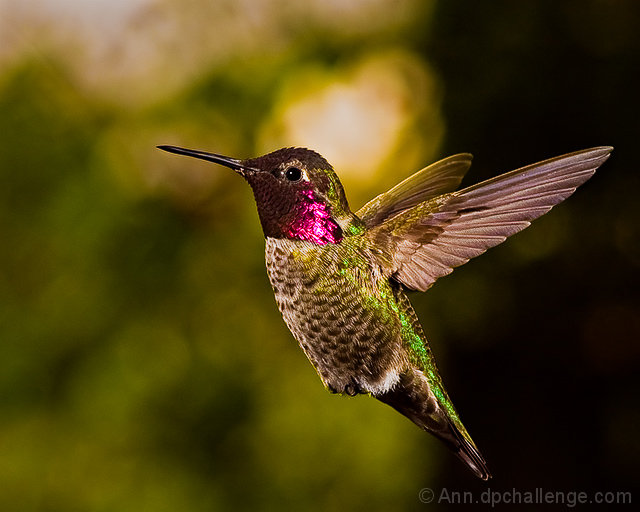

Top 3 Semantic Concept Matches:
  Similarity: 0.272 -> an animal, wildlife, or bird
  Similarity: 0.216 -> a macro close-up of a flower or insect
  Similarity: 0.189 -> a dark moody silhouette
--------------------------------------------------------------------------------

[Rank 5] Image ID: 13873 | Score: 7.8539 | Votes: 219


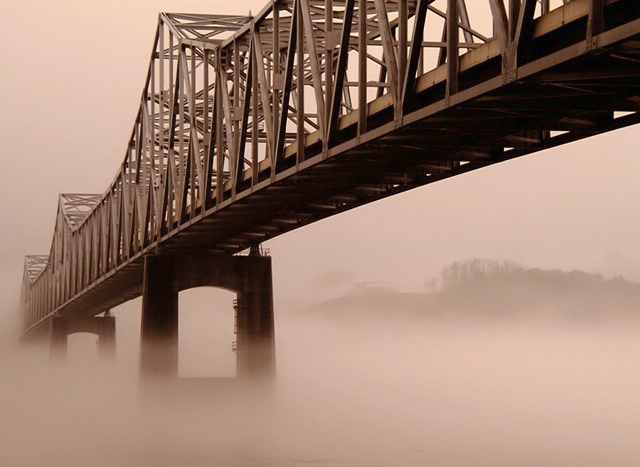

Top 3 Semantic Concept Matches:
  Similarity: 0.224 -> a monochrome black and white photo
  Similarity: 0.221 -> an abstract minimalist composition
  Similarity: 0.218 -> urban street architecture or buildings
--------------------------------------------------------------------------------


In [11]:
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from datasets import load_dataset
from transformers import CLIPModel, CLIPProcessor

# 1. Load your parquet dataset and extract feature vectors
df = pd.read_parquet("data/ava_cleaned_features.parquet")
X_clip = np.vstack(df["clip_embedding"].values).astype(np.float32)
y_mean = df["mean_score"].to_numpy(dtype=np.float32)

# Find top 5 highest-rated image indices and their IDs
top_k = 5
top_indices = np.argsort(y_mean)[::-1][:top_k]
target_ids = set(df.iloc[top_indices]["image_id"].astype(str))

# 2. Candidate concept labels to probe CLIP's semantic alignment
candidate_labels = [
    "an abstract minimalist composition",
    "an animal, wildlife, or bird",
    "a portrait of a human face or person",
    "water, ocean, lake, or sea",
    "a landscape with mountains or trees",
    "urban street architecture or buildings",
    "a dramatic golden sunset or sunrise",
    "a macro close-up of a flower or insect",
    "a dark moody silhouette",
    "a monochrome black and white photo",
]

# 3. Load CLIP text encoder to precompute text vectors
model_id = "openai/clip-vit-base-patch32"
device = "cuda" if torch.cuda.is_available() else "cpu"
model = CLIPModel.from_pretrained(model_id).to(device).eval()
processor = CLIPProcessor.from_pretrained(model_id)

text_inputs = processor(
    text=candidate_labels, return_tensors="pt", padding=True
).to(device)
with torch.no_grad():
    text_outputs = model.text_model(**text_inputs)
    text_embeds = model.text_projection(text_outputs.pooler_output)
    text_embeds = text_embeds / text_embeds.norm(p=2, dim=-1, keepdim=True)
    text_vectors = text_embeds.cpu().numpy()  # Shape: (len(candidate_labels), 512)

# 4. Stream the dataset, display matching images, and print top matched concepts
stream_ds = load_dataset(
    "trojblue/AVA-aesthetics-10pct-min50-10bins", split="train", streaming=True
)
found_images = {}

print("Streaming dataset to find top images...")
for row in stream_ds:
    img_id = str(row["image_id"])
    if img_id in target_ids:
        found_images[img_id] = row["image"]
        if len(found_images) == len(target_ids):
            break

print("=" * 80)
for rank, idx in enumerate(top_indices, start=1):
    row = df.iloc[idx]
    img_id = str(row["image_id"])
    clip_vec = X_clip[idx]

    # Compute cosine similarities (dot product with unit vectors)
    similarities = np.dot(text_vectors, clip_vec)
    sorted_matches = sorted(
        zip(similarities, candidate_labels), key=lambda x: x[0], reverse=True
    )

    print(
        f"\n[Rank {rank}] Image ID: {img_id} | Score: {row['mean_score']:.4f} | Votes: {row['total_votes']}"
    )

    # Display image if retrieved from the stream
    if img_id in found_images:
        display(found_images[img_id])
    else:
        print("  (Image stream missed this ID)")

    print("Top 3 Semantic Concept Matches:")
    for sim, label in sorted_matches[:3]:
        print(f"  Similarity: {sim:.3f} -> {label}")
    print("-" * 80)

Loading CLIP backbone (openai/clip-vit-base-patch32) on cpu...


Loading weights: 100%|██████████| 398/398 [00:00<00:00, 23997.43it/s]


Encoding 1,000 ImageNet prompts into 512-dim unit vectors...
Taxonomy matrix ready. Streaming images from AVA...


c:\Users\Asus\imola\dtu\semester1\datascience\project\aesthetic-unsplash-image-analysis\.venv\Lib\site-packages\PIL\TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 700
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
c:\Users\Asus\imola\dtu\semester1\datascience\project\aesthetic-unsplash-image-analysis\.venv\Lib\site-packages\PIL\TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 33723
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
c:\Users\Asus\imola\dtu\semester1\datascience\project\aesthetic-unsplash-image-analysis\.venv\Lib\site-packages\PIL\TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 34377
  warnings.warn(f"Tag data larger than file. Skipping tag {tag}")
c:\Users\Asus\imola\dtu\semester1\datascience\project\aesthetic-unsplash-image-analysis\.venv\Lib\site-packages\PIL\TiffImagePlugin.py:946: UserWarning: Tag data larger than file. Skipping tag 34675
  warnin

GRANULAR IMAGENET-1K OBJECT RECOGNITION (TOP 5 vs. RANDOM 5)

[TOP] Image ID: 34000 | Score: 8.058 | Total Votes: 137


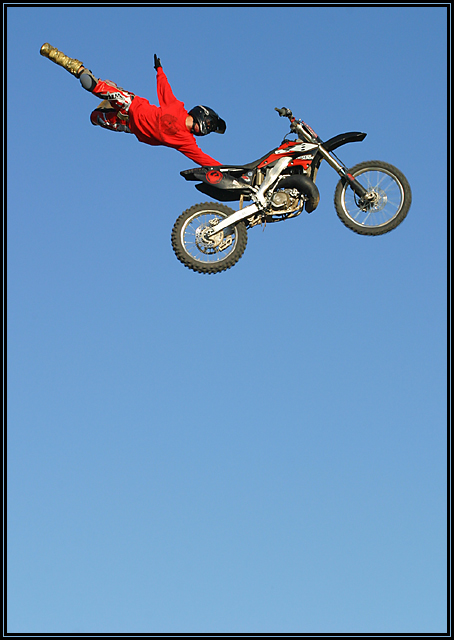

  Top Predicted ImageNet Classes:
    1. 0.272 -> unicycle
    2. 0.267 -> racer
    3. 0.261 -> moped
--------------------------------------------------------------------------------

[TOP] Image ID: 429294 | Score: 8.043 | Total Votes: 230


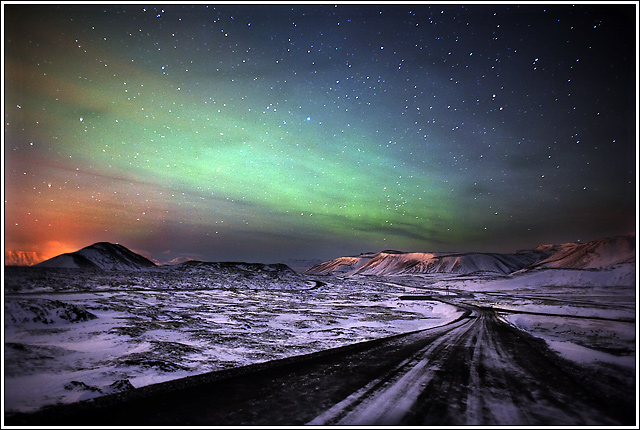

  Top Predicted ImageNet Classes:
    1. 0.258 -> radio telescope
    2. 0.253 -> dogsled
    3. 0.253 -> snowmobile
--------------------------------------------------------------------------------

[TOP] Image ID: 218759 | Score: 7.907 | Total Votes: 492


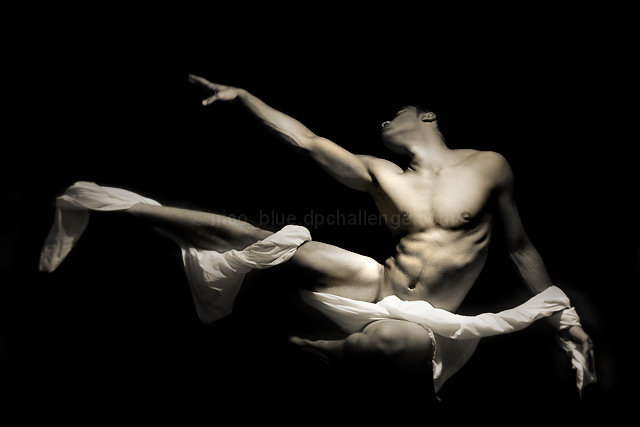

  Top Predicted ImageNet Classes:
    1. 0.255 -> sarong
    2. 0.249 -> parallel bars
    3. 0.245 -> shoji
--------------------------------------------------------------------------------

[TOP] Image ID: 613913 | Score: 7.886 | Total Votes: 166


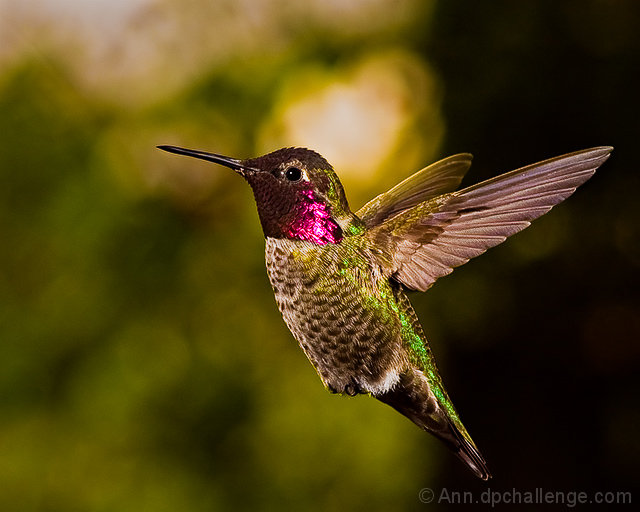

  Top Predicted ImageNet Classes:
    1. 0.334 -> hummingbird
    2. 0.281 -> jacamar
    3. 0.269 -> bulbul
--------------------------------------------------------------------------------

[TOP] Image ID: 13873 | Score: 7.854 | Total Votes: 219


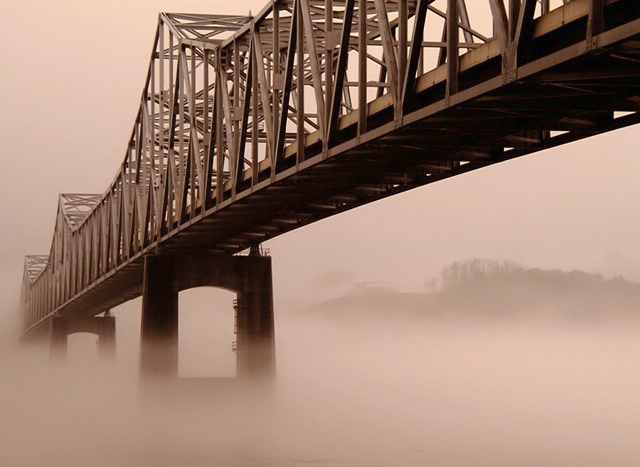

  Top Predicted ImageNet Classes:
    1. 0.285 -> steel arch bridge
    2. 0.279 -> viaduct
    3. 0.276 -> suspension bridge
--------------------------------------------------------------------------------

[RANDOM] Image ID: 479932 | Score: 5.625 | Total Votes: 264


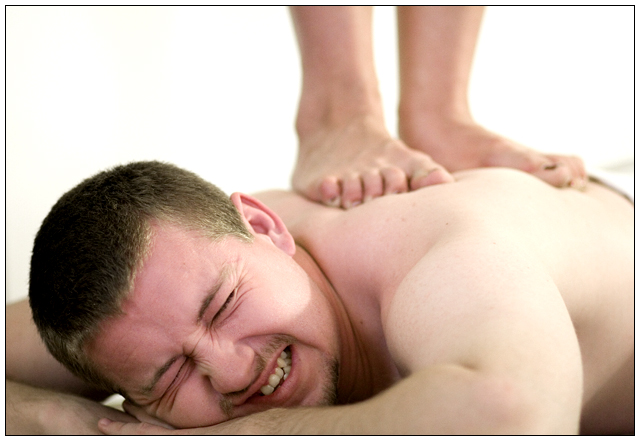

  Top Predicted ImageNet Classes:
    1. 0.259 -> stretcher
    2. 0.251 -> cradle
    3. 0.247 -> punching bag
--------------------------------------------------------------------------------

[RANDOM] Image ID: 937053 | Score: 5.522 | Total Votes: 178


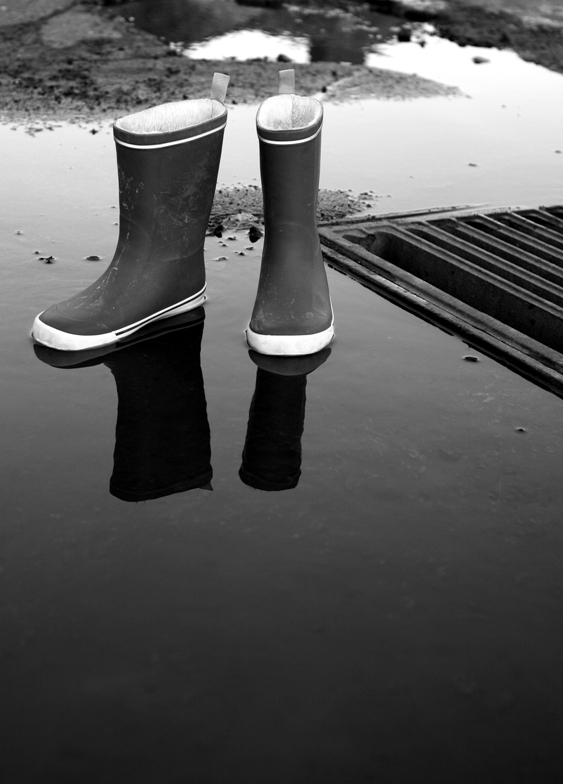

  Top Predicted ImageNet Classes:
    1. 0.288 -> clog
    2. 0.283 -> cowboy boot
    3. 0.276 -> dock
--------------------------------------------------------------------------------

[RANDOM] Image ID: 724616 | Score: 5.632 | Total Votes: 204


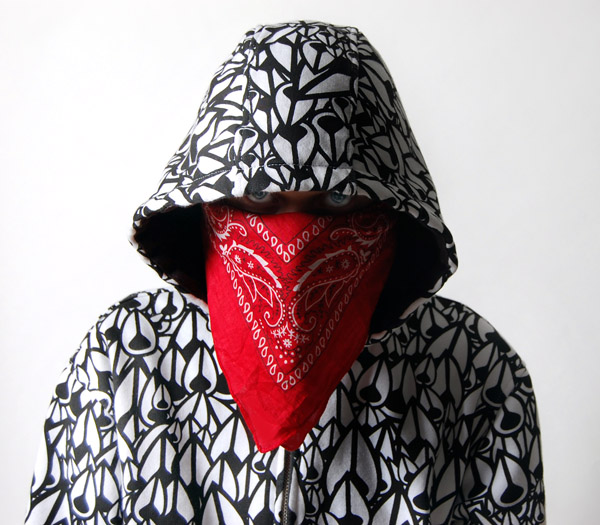

  Top Predicted ImageNet Classes:
    1. 0.291 -> cloak
    2. 0.287 -> ski mask
    3. 0.280 -> poncho
--------------------------------------------------------------------------------

[RANDOM] Image ID: 112188 | Score: 4.416 | Total Votes: 262


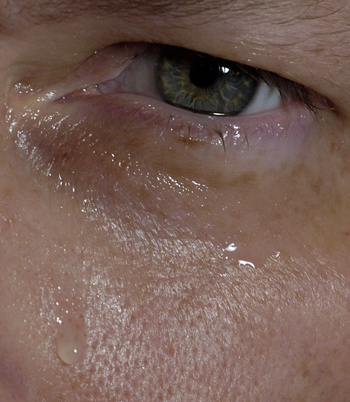

  Top Predicted ImageNet Classes:
    1. 0.238 -> sunscreen
    2. 0.236 -> face powder
    3. 0.234 -> bath towel
--------------------------------------------------------------------------------

[RANDOM] Image ID: 242741 | Score: 5.376 | Total Votes: 205


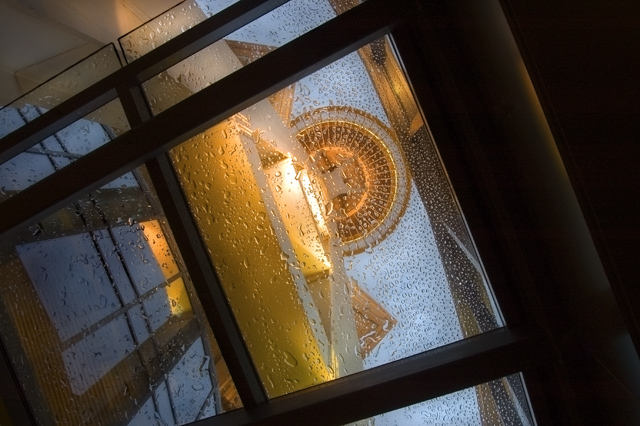

  Top Predicted ImageNet Classes:
    1. 0.286 -> window screen
    2. 0.279 -> window shade
    3. 0.274 -> umbrella
--------------------------------------------------------------------------------


In [13]:
import json
import urllib.request
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from datasets import load_dataset
from transformers import CLIPModel, CLIPProcessor

# 1. Load your parquet dataset and extract feature vectors
df = pd.read_parquet("data/ava_cleaned_features.parquet")
X_clip = np.vstack(df["clip_embedding"].values).astype(np.float32)
y_mean = df["mean_score"].to_numpy(dtype=np.float32)

# Select indices: Top 5 + 5 Randomly Sampled
np.random.seed(42)  # For reproducible random sampling
top_5_indices = np.argsort(y_mean)[::-1][:5].tolist()
remaining_indices = list(set(range(len(df))) - set(top_5_indices))
random_5_indices = np.random.choice(remaining_indices, size=5, replace=False).tolist()

selected_indices = [("TOP", idx) for idx in top_5_indices] + [
    ("RANDOM", idx) for idx in random_5_indices
]
target_ids = set(df.iloc[[idx for _, idx in selected_indices]]["image_id"].astype(str))

# 2. Download and prepare the standard ImageNet-1000 class taxonomy
url = "https://raw.githubusercontent.com/raghakot/keras-vis/master/resources/imagenet_class_index.json"
req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
with urllib.request.urlopen(req) as resp:
    imagenet_raw = json.loads(resp.read().decode())

# Clean labels (replace underscores with spaces)
imagenet_classes = [v[1].replace("_", " ") for v in imagenet_raw.values()]
prompts = [f"a photo of a {cls}" for cls in imagenet_classes]

# 3. Load CLIP text encoder and batch-encode all 1,000 prompts
model_id = "openai/clip-vit-base-patch32"
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Loading CLIP backbone ({model_id}) on {device}...")
model = CLIPModel.from_pretrained(model_id).to(device).eval()
processor = CLIPProcessor.from_pretrained(model_id)

print("Encoding 1,000 ImageNet prompts into 512-dim unit vectors...")
text_vectors_list = []
batch_size = 128

with torch.no_grad():
    for i in range(0, len(prompts), batch_size):
        batch = prompts[i : i + batch_size]
        inputs = processor(text=batch, return_tensors="pt", padding=True).to(device)
        out = model.text_model(**inputs)
        embeds = model.text_projection(out.pooler_output)
        embeds = embeds / embeds.norm(p=2, dim=-1, keepdim=True)
        text_vectors_list.append(embeds.cpu().numpy())

imagenet_matrix = np.vstack(text_vectors_list)  # Shape: (1000, 512)
print("Taxonomy matrix ready. Streaming images from AVA...")

# 4. Stream dataset to grab images for visual inspection
stream_ds = load_dataset(
    "trojblue/AVA-aesthetics-10pct-min50-10bins", split="train", streaming=True
)
found_images = {}
for row in stream_ds:
    img_id = str(row["image_id"])
    if img_id in target_ids:
        found_images[img_id] = row["image"]
        if len(found_images) == len(target_ids):
            break

# 5. Compute similarities and print granular labels
print("=" * 80)
print("GRANULAR IMAGENET-1K OBJECT RECOGNITION (TOP 5 vs. RANDOM 5)")
print("=" * 80)

for tag, idx in selected_indices:
    row = df.iloc[idx]
    img_id = str(row["image_id"])
    clip_vec = X_clip[idx]

    # Cosine similarity across all 1,000 ImageNet classes
    sims = np.dot(imagenet_matrix, clip_vec)
    top_3_class_indices = np.argsort(sims)[::-1][:3]

    header = f"[{tag}] Image ID: {img_id} | Score: {row['mean_score']:.3f} | Total Votes: {row['total_votes']}"
    print(f"\n{header}")

    if img_id in found_images:
        display(found_images[img_id])
    else:
        print("  (Image skipped in current stream window)")

    print("  Top Predicted ImageNet Classes:")
    for rank_c, c_idx in enumerate(top_3_class_indices, start=1):
        print(f"    {rank_c}. {sims[c_idx]:.3f} -> {imagenet_classes[c_idx]}")
    print("-" * 80)

In [5]:

# 1. Feature normalization
# Separate CLIP (already L2-normalized) and structural features
X_clip = np.vstack(df["clip_embedding"].values).astype(np.float32)
X_struct = np.vstack(df["structural_features"].values).astype(np.float32)
y = df["mean_score"].to_numpy(dtype=np.float32)

scaler = StandardScaler()
X_struct_scaled = scaler.fit_transform(X_struct)

# Stack back together: (N, 524)
X = np.hstack([X_clip, X_struct_scaled])

# 2. Train / Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Fit Ridge Regression with 5-fold cross-validation over alpha
alphas = np.logspace(-2, 4, 30)
ridge = RidgeCV(alphas=alphas, cv=5)
ridge.fit(X_train, y_train)

# 4. Evaluate
y_pred = ridge.predict(X_test)
s_corr, _ = spearmanr(y_test, y_pred)
p_corr, _ = pearsonr(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"Optimal Alpha: {ridge.alpha_:.4f}")
print(f"Test RMSE:     {rmse:.4f}")
print(f"Pearson r:     {p_corr:.4f}")
print(f"Spearman rho:  {s_corr:.4f}")

# 5. Persist the trained model and scaler for inference on Unsplash
joblib.dump({"model": ridge, "scaler": scaler}, "models/aesthetic_ridge_model.pkl")

c:\Users\Asus\imola\dtu\semester1\datascience\project\aesthetic-unsplash-image-analysis\.venv\Lib\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 8.706619780696201e-08.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
c:\Users\Asus\imola\dtu\semester1\datascience\project\aesthetic-unsplash-image-analysis\.venv\Lib\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 5.9017466469413193e-08.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
c:\Users\Asus\imola\dtu\semester1\datascience\project\aesthetic-unsplash-image-analysis\.venv\Lib\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 1.0167688202500358e-07.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
c:\Users\Asus\imola\dtu\semester1\datascience\project\aesthetic-unsplash-imag

Optimal Alpha: 1.1721
Test RMSE:     0.5438
Pearson r:     0.6736
Spearman rho:  0.6669


FileNotFoundError: [Errno 2] No such file or directory: 'models/aesthetic_ridge_model.pkl'

In [6]:
from pathlib import Path
import joblib

# Create the directory if it doesn't exist
Path("models").mkdir(parents=True, exist_ok=True)

# Save the trained model and scaler
joblib.dump({"model": ridge, "scaler": scaler}, "models/aesthetic_ridge_model.pkl")
print("Model and scaler saved successfully to models/aesthetic_ridge_model.pkl")

Model and scaler saved successfully to models/aesthetic_ridge_model.pkl
